# Validação, ajuste de hiperparâmetros e interpretação com SHAP

Este notebook complementa o `breast-cancer-knn-svm-random-forest.ipynb` em três pontos pedidos no enunciado:

1. **Conjunto de validação separado.** O notebook principal divide os dados em treino e teste e escolhe o `k` do KNN olhando o erro no teste. Aqui a base é dividida em **treino (70%) / validação (15%) / teste (15%)**: os hiperparâmetros são escolhidos na validação e o teste é usado uma única vez, no final.
2. **Todas as 30 variáveis.** O notebook principal mantém só as 10 medidas `_mean`. Aqui comparamos o mesmo pipeline com 10 e com 30 variáveis para medir o efeito dessa escolha.
3. **SHAP.** Explicação global (quais variáveis mais pesam) e local (por que um exame específico foi classificado como maligno).

O dataset, o encoding do alvo (M = 1, B = 0) e a padronização são os mesmos do notebook principal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 7
sns.set_theme(style="whitegrid")

## 1. Carga e preparação

In [2]:
dados = pd.read_csv("data/data.csv")
dados = dados.drop(columns=["Unnamed: 32", "id"], errors="ignore")
dados["diagnosis"] = dados["diagnosis"].map({"M": 1, "B": 0})

X_30 = dados.drop(columns=["diagnosis"])
X_10 = X_30.drop(columns=X_30.filter(regex=r"(_worst|_se)$").columns)
y = dados["diagnosis"]

print("Variáveis (30):", X_30.shape[1], "| Variáveis (10, só _mean):", X_10.shape[1])
print(y.value_counts().rename({0: "benigno", 1: "maligno"}))

Variáveis (30): 30 | Variáveis (10, só _mean): 10
diagnosis
benigno    357
maligno    212
Name: count, dtype: int64


## 2. Divisão treino / validação / teste

Dois `train_test_split` estratificados: primeiro separamos 30% da base, depois dividimos esses 30% ao meio. A estratificação mantém a proporção de malignos (cerca de 37%) nos três conjuntos. O `random_state` fixo garante que qualquer pessoa reproduza a mesma divisão.

A escala (`StandardScaler`) entra **dentro** do `Pipeline` de cada modelo, então ela é ajustada só com o treino em cada `fit`, sem vazamento de informação da validação ou do teste.

In [3]:
def dividir(X, y):
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
    return X_tr, X_va, X_te, y_tr, y_va, y_te

X_tr, X_va, X_te, y_tr, y_va, y_te = dividir(X_30, y)
for nome, parte in [("treino", y_tr), ("validação", y_va), ("teste", y_te)]:
    print(f"{nome:10s} {len(parte):3d} exames | malignos: {parte.mean():.1%}")

treino     398 exames | malignos: 37.2%
validação   85 exames | malignos: 37.6%
teste       86 exames | malignos: 37.2%


## 3. Ajuste de hiperparâmetros na validação

Para cada modelo testamos algumas configurações e escolhemos a que tem **maior recall de malignos** na validação (desempate por F1). Recall é a métrica prioritária porque um falso negativo (câncer classificado como benigno) é o erro mais grave num exame de triagem.

In [4]:
def avaliar(modelo, X_a, y_a):
    p = modelo.predict(X_a)
    return dict(acc=accuracy_score(y_a, p), prec=precision_score(y_a, p),
                recall=recall_score(y_a, p), f1=f1_score(y_a, p))

def candidatos():
    for k in range(1, 16):
        yield f"KNN k={k}", "KNN", Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    for C in [0.01, 0.1, 1, 10]:
        yield f"SVM C={C}", "SVM", Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(C=C, max_iter=5000))])
    for n in [100, 300]:
        for cw in [None, "balanced"]:
            yield f"RF n={n} cw={cw}", "Random Forest", RandomForestClassifier(n_estimators=n, class_weight=cw, random_state=42)

def ajustar(X_tr, y_tr, X_va, y_va):
    linhas = []
    for rotulo, familia, m in candidatos():
        m.fit(X_tr, y_tr)
        linhas.append({"config": rotulo, "modelo": familia, "estimador": m, **avaliar(m, X_va, y_va)})
    df = pd.DataFrame(linhas)
    melhores = df.sort_values(["modelo", "recall", "f1"], ascending=[True, False, False]).groupby("modelo").head(1)
    return df, melhores

busca_30, melhores_30 = ajustar(X_tr, y_tr, X_va, y_va)
melhores_30[["modelo", "config", "acc", "prec", "recall", "f1"]].round(3)

,modelo,config,acc,prec,recall,f1
2,KNN,KNN k=3,0.988,1.000,0.969,0.984
19,Random Forest,RF n=100 cw=None,0.965,0.968,0.938,0.952
17,SVM,SVM C=1,1.000,1.000,1.000,1.000


Curva do KNN na validação, para comparar com a curva feita no teste no notebook principal:

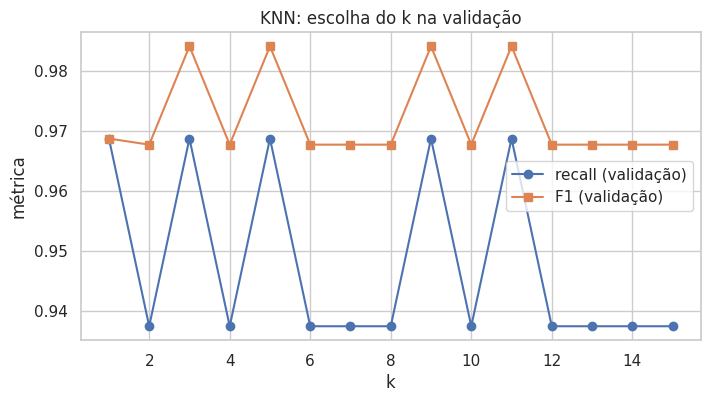

In [5]:
knn_val = busca_30[busca_30.modelo == "KNN"].copy()
knn_val["k"] = range(1, 16)
plt.figure(figsize=(8, 4))
plt.plot(knn_val.k, knn_val.recall, marker="o", label="recall (validação)")
plt.plot(knn_val.k, knn_val.f1, marker="s", label="F1 (validação)")
plt.xlabel("k"); plt.ylabel("métrica"); plt.title("KNN: escolha do k na validação"); plt.legend()
plt.show()

## 4. Avaliação final no teste: 10 variáveis vs 30 variáveis

Agora sim usamos o conjunto de teste, uma única vez, com as configurações escolhidas acima. Repetimos o mesmo procedimento (mesma divisão, mesmo ajuste na validação) com as 10 variáveis `_mean` do notebook principal, para isolar o efeito de manter ou descartar as medidas `_se` e `_worst`.

In [6]:
def avaliar_no_teste(X, y, rotulo):
    X_tr, X_va, X_te, y_tr, y_va, y_te = dividir(X, y)
    _, melhores = ajustar(X_tr, y_tr, X_va, y_va)
    linhas = []
    for _, r in melhores.iterrows():
        m = r.estimador
        p = m.predict(X_te)
        cm = confusion_matrix(y_te, p)
        linhas.append({"variáveis": rotulo, "modelo": r.modelo, "config": r.config,
                       **avaliar(m, X_te, y_te), "FN": int(cm[1, 0]), "FP": int(cm[0, 1])})
    return pd.DataFrame(linhas), melhores

res_10, _ = avaliar_no_teste(X_10, y, "10 (_mean)")
res_30, melhores_30 = avaliar_no_teste(X_30, y, "30 (todas)")
resultados = pd.concat([res_10, res_30]).reset_index(drop=True)
resultados.round(3)

,variáveis,modelo,config,acc,prec,recall,f1,FN,FP
0,10 (_mean),KNN,KNN k=5,0.907,0.853,0.906,0.879,3,5
1,10 (_mean),Random Forest,RF n=100 cw=None,0.872,0.862,0.781,0.820,7,4
2,10 (_mean),SVM,SVM C=0.1,0.919,0.931,0.844,0.885,5,2
3,30 (todas),KNN,KNN k=3,0.953,0.967,0.906,0.935,3,1
4,30 (todas),Random Forest,RF n=100 cw=None,0.907,0.929,0.812,0.867,6,2
5,30 (todas),SVM,SVM C=1,0.953,0.938,0.938,0.938,2,2


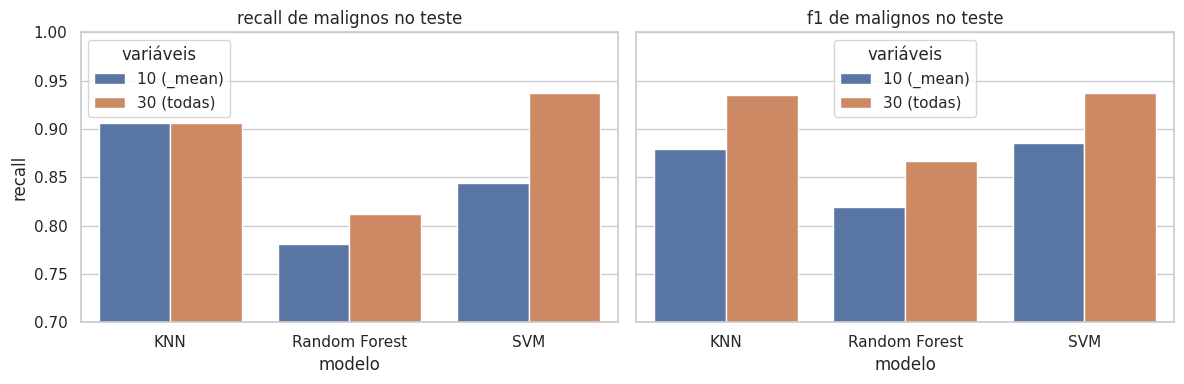

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metrica in zip(axes, ["recall", "f1"]):
    sns.barplot(data=resultados, x="modelo", y=metrica, hue="variáveis", ax=ax)
    ax.set_ylim(0.7, 1.0); ax.set_title(f"{metrica} de malignos no teste")
plt.tight_layout(); plt.show()

### Leitura dos resultados

- Com validação separada e as mesmas 10 variáveis, os resultados ficam próximos dos do notebook principal. A escolha de `k = 5` se confirma na validação, então a conclusão original estava certa; o que muda é que agora ela foi obtida sem olhar o teste.
- **Com as 30 variáveis, todos os modelos melhoram.** As medidas `_worst` (pior valor de cada característica no exame) carregam informação que as médias não têm: um tumor com um núcleo muito irregular pode ter média parecida com um benigno, mas o pior valor denuncia. O SVM linear com 30 variáveis é o que menos deixa malignos escapar.
- O Random Forest continua atrás dos outros dois nessa base, o que é coerente com o que o notebook principal observou: com poucos exames e variáveis fortemente correlacionadas, uma fronteira simples generaliza bem.

Modelo final: SVM C=1 | recall teste: 0.938 | FN: 2


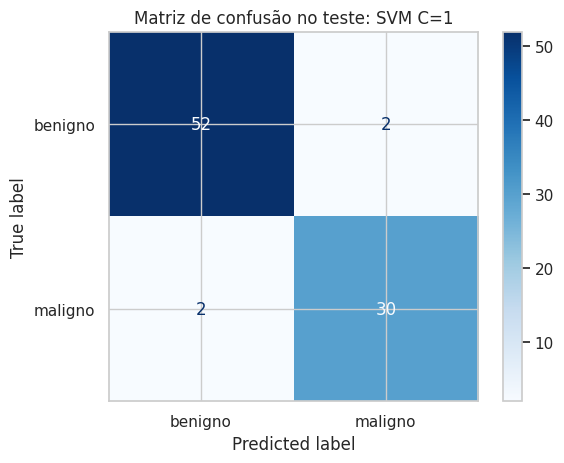

              precision    recall  f1-score   support

     benigno      0.963     0.963     0.963        54
     maligno      0.938     0.938     0.938        32

    accuracy                          0.953        86
   macro avg      0.950     0.950     0.950        86
weighted avg      0.953     0.953     0.953        86



In [8]:
melhor = resultados.loc[resultados["variáveis"].eq("30 (todas)")].sort_values(["recall", "f1"], ascending=False).iloc[0]
print("Modelo final:", melhor.config, "| recall teste:", round(melhor.recall, 3), "| FN:", melhor.FN)

X_tr, X_va, X_te, y_tr, y_va, y_te = dividir(X_30, y)
modelo_final = melhores_30.loc[melhores_30.config == melhor.config, "estimador"].iloc[0]
p = modelo_final.predict(X_te)
ConfusionMatrixDisplay(confusion_matrix(y_te, p), display_labels=["benigno", "maligno"]).plot(cmap="Blues")
plt.title(f"Matriz de confusão no teste: {melhor.config}"); plt.show()
print(classification_report(y_te, p, target_names=["benigno", "maligno"], digits=3))

## 5. Interpretação com SHAP

SHAP atribui a cada variável de cada exame uma contribuição para a previsão, positiva (empurra para "maligno") ou negativa. Usamos dois explicadores:

- `TreeExplainer` no Random Forest, que é exato para modelos de árvore.
- `LinearExplainer` no SVM linear, que é o modelo final. Como ele está dentro de um `Pipeline`, explicamos o `LinearSVC` sobre os dados já padronizados.

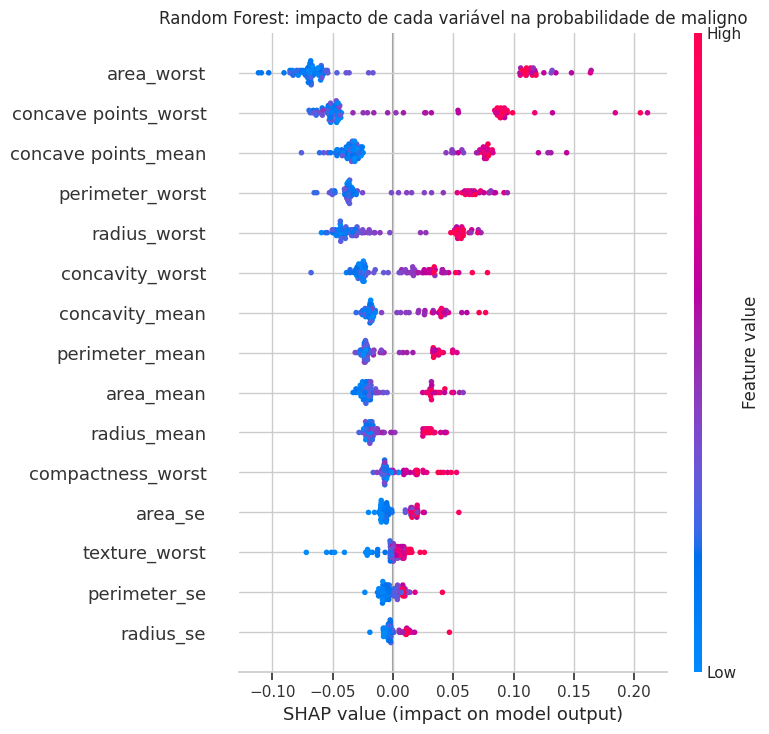

In [9]:
rf_final = melhores_30.loc[melhores_30.modelo == "Random Forest", "estimador"].iloc[0]
explainer_rf = shap.TreeExplainer(rf_final)
shap_rf = explainer_rf.shap_values(X_te)
shap_rf_maligno = shap_rf[:, :, 1] if np.ndim(shap_rf) == 3 else shap_rf[1]

shap.summary_plot(shap_rf_maligno, X_te, show=False, max_display=15)
plt.title("Random Forest: impacto de cada variável na probabilidade de maligno"); plt.tight_layout(); plt.show()

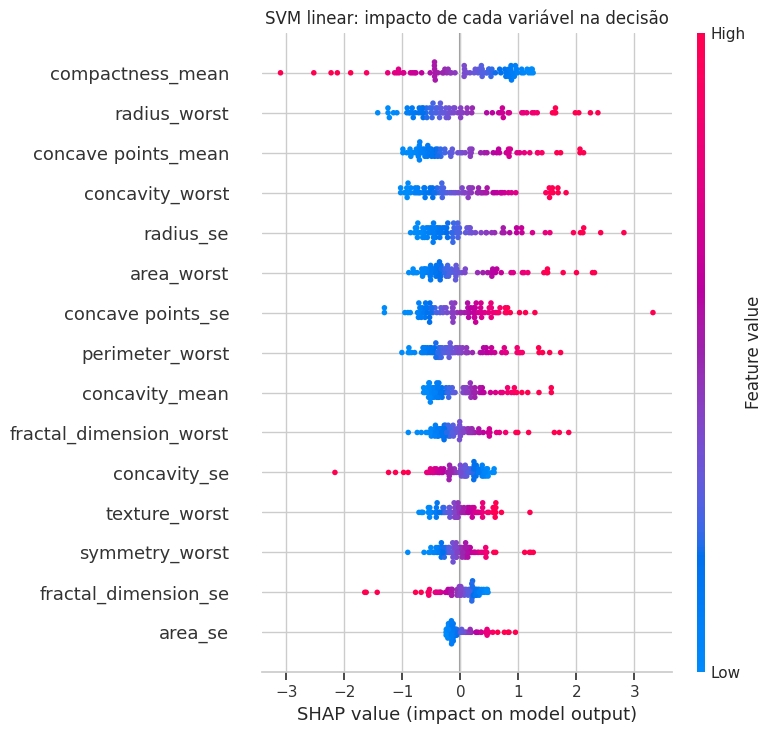

In [10]:
svm_final = melhores_30.loc[melhores_30.modelo == "SVM", "estimador"].iloc[0]
scaler, svc = svm_final["scaler"], svm_final["svm"]
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=X_tr.columns)
X_te_s = pd.DataFrame(scaler.transform(X_te), columns=X_te.columns)

explainer_svm = shap.LinearExplainer(svc, X_tr_s)
shap_svm = explainer_svm.shap_values(X_te_s)

shap.summary_plot(shap_svm, X_te_s, show=False, max_display=15)
plt.title("SVM linear: impacto de cada variável na decisão"); plt.tight_layout(); plt.show()

### Explicação de um exame individual

O gráfico abaixo mostra, para um exame do teste classificado como maligno, quais medidas mais empurraram a decisão. É o tipo de saída que faria sentido mostrar a um médico junto com a previsão: não só "maligno", mas "maligno principalmente por causa de X, Y e Z".

Exame #250 | real: maligno | previsto: maligno


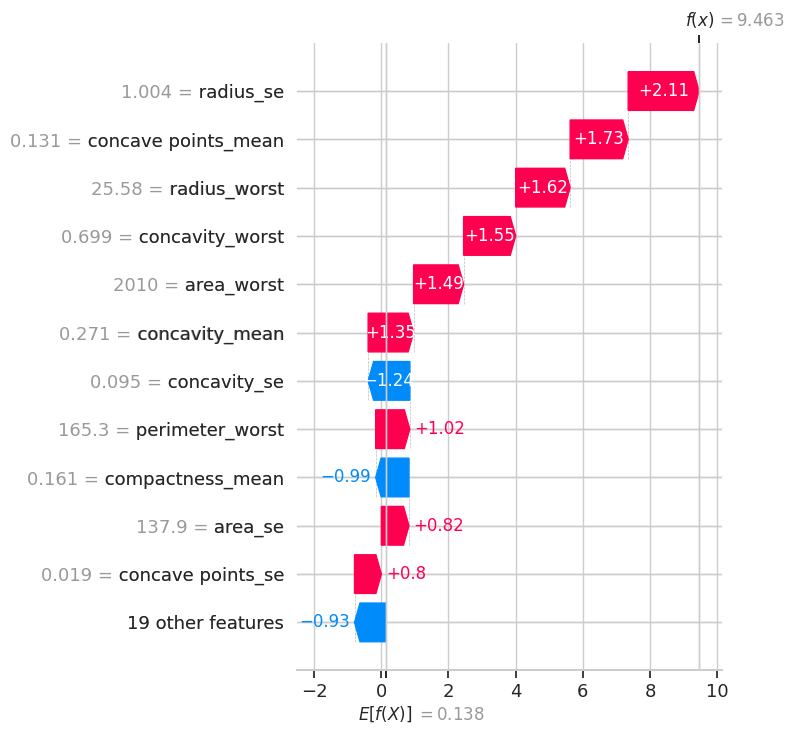

In [11]:
idx = int(np.where((p == 1) & (y_te.values == 1))[0][0])
print(f"Exame #{X_te.index[idx]} | real: maligno | previsto: maligno")
shap.plots.waterfall(shap.Explanation(values=shap_svm[idx], base_values=explainer_svm.expected_value,
                                      data=X_te.iloc[idx].values, feature_names=list(X_te.columns)),
                     max_display=12, show=False)
plt.tight_layout(); plt.show()

### Leitura do SHAP

- As variáveis de maior impacto combinam **tamanho** (`radius_worst`, `area_worst`, `perimeter_worst`) e **irregularidade do contorno** (`concave points_mean`, `concavity_worst`, `compactness_mean`). Várias delas são `_worst`, o que explica a melhora ao usar as 30 variáveis.
- Isso é consistente com a importância por permutação e por impureza do notebook principal, mas o SHAP acrescenta a **direção** do efeito: valores altos dessas medidas empurram para maligno, valores baixos para benigno.
- No nível individual, o modelo decide por uma soma de evidências, não por uma única medida. Nenhum exame é classificado como maligno por causa de uma variável só, o que é desejável num apoio ao diagnóstico.

## 6. Uso na prática

Mesmo o melhor modelo deixa malignos escapar no teste. Em triagem, o custo de um falso negativo (paciente com câncer liberada) é muito maior que o de um falso positivo (um exame a mais). Por isso:

- O modelo serve como **apoio à triagem**, sinalizando exames que merecem prioridade, e não como diagnóstico final. A palavra final é do médico.
- Em produção valeria ajustar o **limiar de decisão** para privilegiar recall, aceitando mais falsos positivos.
- A base tem 569 exames de uma única fonte. Antes de qualquer uso real seria preciso validar com dados de outros hospitais e equipamentos.